# HackINE — 01 · Auditoría de las seis bases

Auditoría de origen, tamaños, consistencia y datos no especificados. Este notebook lee los reportes creados mediante `python -m src.pipeline`; la auditoría original de los 192 archivos estatales se implementa en `src/pipeline.py`.

Fuente: ZIPs CCPC del INE conservados en `datos/raw/`. Se trabaja sobre sus agregaciones verificables en `datos/processed/`. Los resultados representan **grupos estadísticos, no personas individuales**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'datos').exists():
    ROOT = ROOT.parent.parent
assert (ROOT/'datos'/'processed').exists(), f'Abra el proyecto raíz, no otro directorio: {ROOT}'
plt.rcParams.update({'figure.figsize':(9,4.3),'figure.dpi':110})


## Inventario 2009–2024 y aritmética de los conteos

In [2]:
a = pd.read_csv(ROOT/'analisis/reportes/auditoria_resumen.csv')
cols=['anio','filas','municipios','LN','SV','NV','NS','count_inconsistent','count_negative','unobserved_rows']
display(a[cols]); print('TOTAL FILAS:',f'{a.filas.sum():,}'); print('Errores aritméticos:',a.count_inconsistent.sum())

,anio,filas,municipios,LN,SV,NV,NS,count_inconsistent,count_negative,unobserved_rows
0,2009,8706843,2458,77481831,33316974,42298963,1865894,0,0,142141
1,2012,8604456,2455,76490962,47383154,28939159,168649,0,0,9839
2,2015,9106059,2458,83563462,36926612,41517874,5118976,0,0,309186
3,2018,9251122,2463,89123997,51784399,31249856,6089742,0,0,363901
4,2021,9430502,2468,93532133,46389189,43099624,4043320,0,0,246681
5,2024,9773730,2477,98330348,54899228,37105466,6325654,0,0,323984


TOTAL FILAS: 54,872,712
Errores aritméticos: 0


## Fuentes, hash SHA-256 y campos faltantes

In [3]:
import json
for year in a.anio:
    d=json.loads((ROOT/f'datos/processed/{year}/auditoria.json').read_text())
    print(year,' | zip=',d['original_zip'].split('/')[-1], '| SHA256=',d['sha256_zip'][:16], '| faltantes=',d['faltantes_por_columna'])

2009  | zip= DatosAbiertos_DECEyEC_ConteosCensales2009.zip | SHA256= e626e9528a91206c | faltantes= {}
2012  | zip= DatosAbiertos_DECEyEC_ConteosCensales2012.zip | SHA256= 5999f86e21154138 | faltantes= {}
2015  | zip= DatosAbiertos_DECEyEC_ConteosCensales2015.zip | SHA256= 7435ac54a3a6aebf | faltantes= {}
2018  | zip= DatosAbiertos_DECEyEC_ConteosCensales2018.zip | SHA256= b20981a0aea1ac77 | faltantes= {}
2021  | zip= DatosAbiertos_DECEyEC_ConteosCensales2021.zip | SHA256= 29bdfaaa33be5151 | faltantes= {}
2024  | zip= DatosAbiertos_DECEyEC_ConteosCensales2024.zip | SHA256= c0de34d04e782ad9 | faltantes= {'DEL': 20912}


## Proporción de registros sin marca conocida

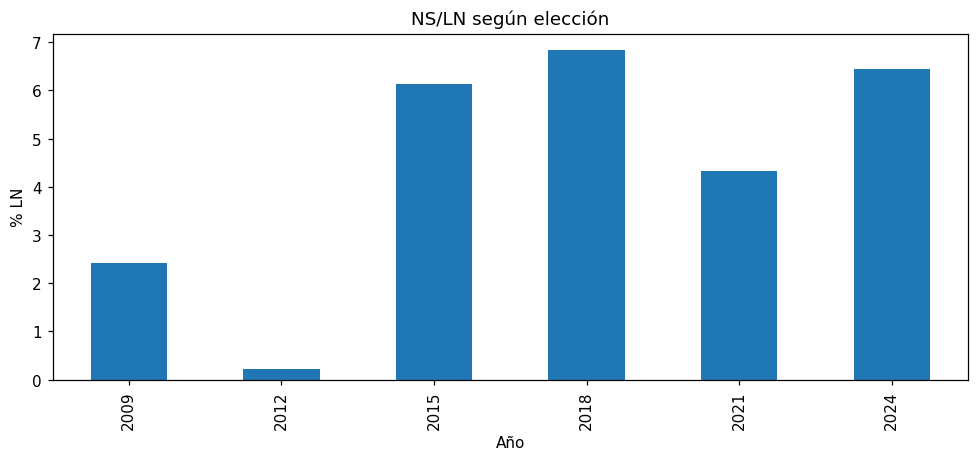

NS significa no especificado: no debe contarse como abstención.


In [4]:
n=pd.read_csv(ROOT/'analisis/reportes/resumen_nacional.csv')
ax=n.plot.bar(x='anio',y='ns_pct',legend=False);ax.set(title='NS/LN según elección',ylabel='% LN',xlabel='Año')
plt.tight_layout();plt.show()
print('NS significa no especificado: no debe contarse como abstención.')

## Comparaciones cuidadosas entre tipos de elección

In [5]:
display(n[['anio','tipo','participacion_pct','ns_pct']].round(2))
print('No comparar 2012→2015 como tendencia directa: elecciones de naturaleza distinta.')

,anio,tipo,participacion_pct,ns_pct
0,2009,Intermedia,44.06,2.41
1,2012,Presidencial,62.08,0.22
2,2015,Intermedia,47.07,6.13
3,2018,Presidencial,62.37,6.83
4,2021,Intermedia,51.84,4.32
5,2024,Presidencial,59.67,6.43


No comparar 2012→2015 como tendencia directa: elecciones de naturaleza distinta.
